# Baseball Strategy Agent
**Ospanov Dayan | 23B030308 | CSCI3235 Midterm I**

Can SARSA learn when to swing and when to take a pitch? This notebook trains a
small agent and compares it with simple strategies. Everything needed to run
the experiment is here. Run the cells in order with a Python 3 kernel that has
NumPy and Matplotlib installed.

## 1. The problem
The batter makes a decision before each pitch. Taking can move the count toward
a walk or a strikeout; swinging can end the at-bat or add a strike. The aim is to
finish with a hit or walk. This connects the project to sports analytics, although
the simulator is deliberately simple and is not a real batting adviser.

RL can learn from sampled at-bats without knowing the probabilities. If the model
is already known and this small, dynamic programming is a more direct non-RL
alternative.

| MDP component | Definition |
|:--|:--|
| State | `(balls, strikes)`: 0-3 balls and 0-2 strikes, giving 12 states |
| Actions | `0 = Take`, `1 = Swing` |
| Start | `(0, 0)` |
| End | Hit, walk, strikeout, or other out |
| Reward | +1 for a hit/walk, -1 for an out/strikeout, otherwise 0 |
| Discount | 1.0, so the objective is the terminal outcome |

Taking produces a ball with probability 0.40 and a called strike with probability
0.60. Swinging produces a hit (0.24), other out (0.18), foul (0.20), or miss (0.38).
A foul adds a strike unless there are already two strikes. These are fixed
synthetic probabilities, not baseball statistics; they are unchanged from the
original project.

For example: `(2, 1) -- Take, ball, reward 0 --> (3, 1)`, with probability 0.40.
The environment is stochastic and episodic. The count is Markov under these fixed
assumptions; real baseball also depends on pitcher, batter, pitch location, and
history. A 30-pitch limit stops an unusually long simulation. It is a truncation,
not an additional out, so SARSA still uses the next-state value at that limit.


In [1]:
%matplotlib inline
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

STATES = [(balls, strikes) for balls in range(4) for strikes in range(3)]
SEEDS = [42, 123, 456, 789, 2026]
EPISODES = 10000
EVAL_EPISODES = 10000
MAX_PITCHES = 30
ALPHA = 0.1
GAMMA = 1.0
EPSILONS = [0.05, 0.2, 0.5]
MAIN_EPSILON = 0.2


## 2. Environment
`step` takes the current count and action and returns the next count, reward,
and whether the at-bat ended. `None` represents a terminal state. The training
and evaluation loops handle the 30-pitch safety limit separately.


In [2]:
def step(state, action, rng):
    balls, strikes = state
    chance = rng.random()

    if action == 0:
        if chance < 0.4:
            balls += 1
        else:
            strikes += 1
    else:
        if chance < 0.24:
            return None, 1, True
        if chance < 0.42:
            return None, -1, True
        if chance < 0.62:
            strikes = min(strikes + 1, 2)
        else:
            strikes += 1

    if balls == 4:
        return None, 1, True
    if strikes == 3:
        return None, -1, True
    return (balls, strikes), 0, False


### AI-assisted verification: foul with two strikes
OpenAI Codex added and executed this check. A fixed random draw of 0.50 selects the foul branch (0.42 to below 0.62). With two strikes, the count should stay unchanged, reward should be zero, and the episode should continue.


In [3]:
from unittest.mock import Mock

foul_rng = Mock()
foul_rng.random.return_value = 0.50
foul_result = step((0, 2), 1, foul_rng)
assert foul_result == ((0, 2), 0, False)
print("PASS: two-strike foul ->", foul_result)


PASS: two-strike foul -> ((0, 2), 0, False)


## 3. SARSA
The Q-table has two values per state: one for Take and one for Swing. During
training, epsilon-greedy action selection sometimes explores; otherwise it picks
the larger Q-value. Equal training values are broken randomly.

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[r+\gamma Q(s',a')-Q(s,a)]$$

Here, $s,a$ are the current state and action, $r$ is the observed reward, and
$s',a'$ are the next state and the next action actually selected. $\alpha$ is
the learning rate and $\gamma$ discounts future rewards. The bracket is the
temporal-difference error. The future value is zero at a true terminal state.

SARSA estimates returns under its training policy; it does not replace the next
action's value with the maximum. With epsilon 0.2, a unique greedy action has
probability 0.9 because random exploration can also select it. Alpha and epsilon
stay constant, so this experiment does not guarantee convergence to the optimum.


In [4]:
def choose_action(q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.choice([0, 1])
    if q[state][0] == q[state][1]:
        return rng.choice([0, 1])
    return 1 if q[state][1] > q[state][0] else 0


def train(seed, epsilon):
    rng = random.Random(seed)
    action_rng = random.Random(seed + 1000000)
    q = {state: [0.0, 0.0] for state in STATES}
    rewards = []
    timeouts = 0

    for episode in range(EPISODES):
        state = (0, 0)
        action = choose_action(q, state, epsilon, action_rng)

        for pitch in range(MAX_PITCHES):
            next_state, reward, done = step(state, action, rng)
            if done:
                target = reward
            else:
                next_action = choose_action(q, next_state, epsilon, action_rng)
                target = reward + GAMMA * q[next_state][next_action]

            q[state][action] += ALPHA * (target - q[state][action])
            if done:
                break
            state, action = next_state, next_action

        rewards.append(reward)
        timeouts += int(not done)

    return q, rewards, timeouts


## 4. Separate evaluation and baselines
Evaluation freezes the learned Q-table and selects its greedy action. Evaluation
ties choose Take. The baselines choose randomly, take until two strikes, or always
swing. Always-swing is included because it is a strong simple comparison in this
particular model.

Each run uses fresh evaluation seeds. A hit or walk counts as success; an at-bat
that reaches the safety limit is recorded as a timeout. No learning takes place
inside `evaluate`.


In [5]:
def evaluate(policy, seed, q=None):
    rng = random.Random(seed)
    action_rng = random.Random(seed + 10000000)
    wins = 0
    total_reward = 0
    total_pitches = 0
    timeouts = 0

    for episode in range(EVAL_EPISODES):
        state = (0, 0)
        for pitch in range(MAX_PITCHES):
            if policy == "Random":
                action = action_rng.choice([0, 1])
            elif policy == "Fixed rule":
                action = 1 if state[1] == 2 else 0
            elif policy == "Always swing":
                action = 1
            else:
                action = 1 if q[state][1] > q[state][0] else 0

            state, reward, done = step(state, action, rng)
            total_reward += reward
            if done:
                wins += int(reward == 1)
                break

        total_pitches += pitch + 1
        timeouts += int(not done)

    return {
        "success": wins / EVAL_EPISODES,
        "reward": total_reward / EVAL_EPISODES,
        "pitches": total_pitches / EVAL_EPISODES,
        "timeouts": timeouts,
    }


## 5. Run the experiment
Train 10,000 at-bats for each of five seed labels and three epsilon settings.
Ten thousand episodes is a practical budget for a 24-entry Q-table, not proof of
convergence. Compare epsilon 0.05, 0.20, and 0.50 while holding everything else fixed.

Training uses `seed` for transitions and `seed + 1000000` for actions. SARSA's
final evaluation uses `seed + 3000000`. Baselines use `seed + 4000000 + index *
100000`; evaluation actions use a further offset of 10000000. Reusing seed labels
across epsilon settings gives reproducible comparisons, but trajectories differ
when actions differ. All five seeds are reported; the last trained policy is used
without selecting a favorable checkpoint.


In [6]:
results = {}
histories = {}
q_tables = {}
training_timeouts = 0

for epsilon in EPSILONS:
    name = f"SARSA eps={epsilon:g}"
    results[name] = []
    histories[epsilon] = []
    q_tables[epsilon] = []

    for seed in SEEDS:
        q, rewards, timeouts = train(seed, epsilon)
        q_tables[epsilon].append(q)
        histories[epsilon].append(rewards)
        training_timeouts += timeouts
        results[name].append(evaluate("SARSA", seed + 3000000, q))

for index, name in enumerate(["Random", "Fixed rule", "Always swing"]):
    results[name] = []
    for seed in SEEDS:
        results[name].append(evaluate(name, seed + 4000000 + index * 100000))

evaluation_timeouts = sum(row["timeouts"] for runs in results.values() for row in runs)
print("Finished training 15 agents and evaluating all policies.")
print("Training timeouts:", training_timeouts)
print("Evaluation timeouts:", evaluation_timeouts)


Finished training 15 agents and evaluating all policies.
Training timeouts: 0
Evaluation timeouts: 0


In [7]:
def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


summary = {}
rows = []
for name, runs in results.items():
    success = [run["success"] for run in runs]
    summary[name] = [np.mean(success), np.std(success, ddof=1)]
    rows.append([
        name,
        f"{100 * np.mean(success):.2f}",
        f"{100 * np.std(success, ddof=1):.2f}",
        f"{np.mean([run['reward'] for run in runs]):.4f}",
        f"{np.mean([run['pitches'] for run in runs]):.3f}",
    ])

show_table(["Policy", "Success (%)", "SD (percentage points)", "Mean reward", "Mean pitches"], rows)


| Policy | Success (%) | SD (percentage points) | Mean reward | Mean pitches |
| --- | --- | --- | --- | --- |
| SARSA eps=0.05 | 39.98 | 1.44 | -0.2004 | 3.193 |
| SARSA eps=0.2 | 40.87 | 6.05 | -0.1826 | 3.094 |
| SARSA eps=0.5 | 43.07 | 3.76 | -0.1386 | 2.904 |
| Random | 36.28 | 0.28 | -0.2744 | 2.928 |
| Fixed rule | 36.30 | 0.73 | -0.2739 | 4.288 |
| Always swing | 47.47 | 0.51 | -0.0506 | 2.013 |

## 6. Training and final performance
The training curve uses nonoverlapping windows of 250 at-bats. Shading and error
bars show one sample standard deviation across the five seeds, not confidence
intervals. Training still includes exploratory actions; final evaluation is greedy.


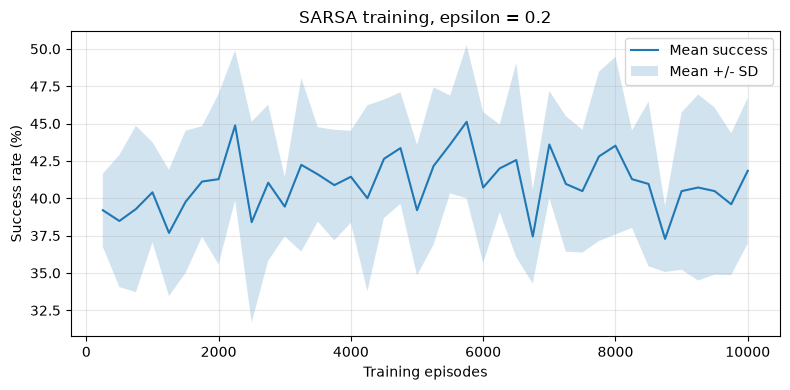

In [8]:
window = 250
curves = []
for rewards in histories[MAIN_EPSILON]:
    successes = np.array(rewards) > 0
    curves.append(successes.reshape(-1, window).mean(axis=1) * 100)

curves = np.array(curves)
x = np.arange(window, EPISODES + 1, window)
average = curves.mean(axis=0)
spread = curves.std(axis=0, ddof=1)

plt.figure(figsize=(8, 4))
plt.plot(x, average, label="Mean success")
plt.fill_between(x, average - spread, average + spread, alpha=0.2, label="Mean +/- SD")
plt.xlabel("Training episodes")
plt.ylabel("Success rate (%)")
plt.title("SARSA training, epsilon = 0.2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


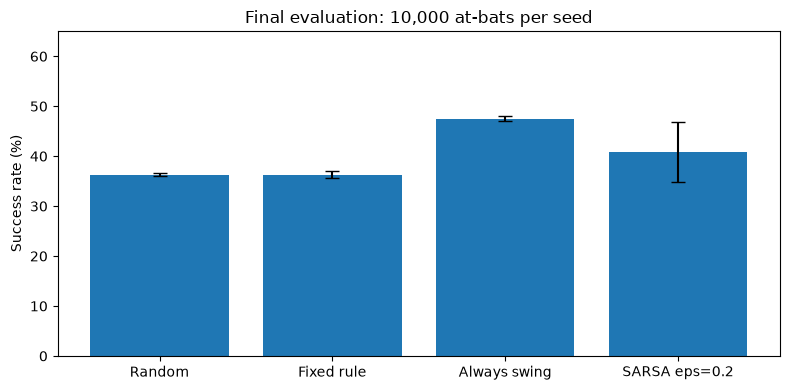

In [9]:
names = ["Random", "Fixed rule", "Always swing", "SARSA eps=0.2"]
means = [100 * summary[name][0] for name in names]
errors = [100 * summary[name][1] for name in names]

plt.figure(figsize=(8, 4))
plt.bar(names, means, yerr=errors, capsize=5)
plt.ylabel("Success rate (%)")
plt.title("Final evaluation: 10,000 at-bats per seed")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()


### What happened?
At epsilon 0.20, SARSA reaches **40.87% +/- 6.05 percentage points** success.
Random reaches 36.28%, the fixed rule 36.30%, and always-swing 47.47%. SARSA has
a higher mean than the two weaker baselines, but it does not beat always-swing.
The variation between seeds is substantial, so this is not a claim of statistically
significant improvement. The training curve fluctuates rather than steadily converging.

With no timeouts, mean reward is `2 * success_rate - 1`. A negative reward therefore
does not mean that training failed to run; it means fewer than half of the at-bats
were successful.


## 7. Epsilon sensitivity and policy table
The table above includes all three epsilon settings. The following plot changes
only training epsilon; every final policy is evaluated greedily. The policy grid
shows seed 42, selected in advance as the first seed, rather than the best run.


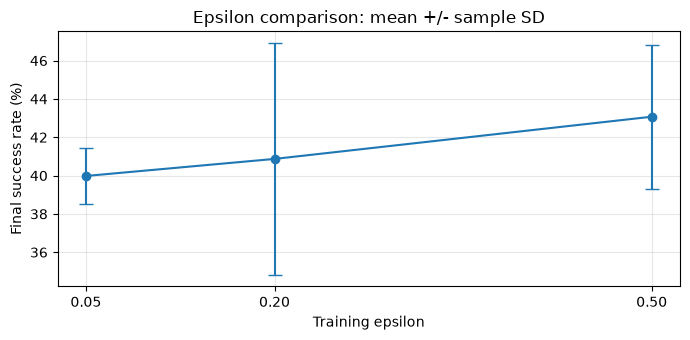

| Balls | 0 strikes | 1 strike | 2 strikes |
| --- | --- | --- | --- |
| 0 | Swing | Take | Swing |
| 1 | Take | Swing | Swing |
| 2 | Take | Swing | Swing |
| 3 | Take | Take | Swing |

In [10]:
means = [100 * summary[f"SARSA eps={epsilon:g}"][0] for epsilon in EPSILONS]
errors = [100 * summary[f"SARSA eps={epsilon:g}"][1] for epsilon in EPSILONS]

plt.figure(figsize=(7, 3.5))
plt.errorbar(EPSILONS, means, yerr=errors, fmt="o-", capsize=5)
plt.xticks(EPSILONS)
plt.xlabel("Training epsilon")
plt.ylabel("Final success rate (%)")
plt.title("Epsilon comparison: mean +/- sample SD")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

q = q_tables[MAIN_EPSILON][0]
rows = []
for balls in range(4):
    row = [balls]
    for strikes in range(3):
        values = q[(balls, strikes)]
        row.append("Swing" if values[1] > values[0] else "Take")
    rows.append(row)

show_table(["Balls", "0 strikes", "1 strike", "2 strikes"], rows)


In [11]:
rows = []
for index, seed in enumerate(SEEDS):
    row = [seed]
    for epsilon in EPSILONS:
        score = results[f"SARSA eps={epsilon:g}"][index]["success"]
        row.append(f"{100 * score:.2f}")
    rows.append(row)

show_table(["Seed", "eps=0.05 success (%)", "eps=0.20 success (%)", "eps=0.50 success (%)"], rows)


| Seed | eps=0.05 success (%) | eps=0.20 success (%) | eps=0.50 success (%) |
| --- | --- | --- | --- |
| 42 | 38.27 | 44.02 | 42.29 |
| 123 | 41.92 | 43.92 | 41.86 |
| 456 | 39.05 | 41.40 | 48.34 |
| 789 | 40.81 | 44.73 | 44.70 |
| 2026 | 39.85 | 30.28 | 38.17 |

## 8. Discussion and limitations
Epsilon 0.50 has the highest observed SARSA mean (43.07%), compared with 39.98% at
0.05 and 40.87% at 0.20. More exploration may improve coverage, but it also changes
the policy whose values SARSA estimates. The experiment does not isolate the cause
or establish a universally best epsilon. The main setting stays at 0.20.

Seed 2026 at epsilon 0.20 reaches only 30.28%, showing that a single successful
run would be misleading. A constant learning rate keeps estimates sensitive to
recent outcomes. A useful next experiment would predefine decaying alpha and
epsilon schedules and test them with more seeds.

The transition model is also a limitation. It ignores pitcher/batter differences
and treats a walk and every hit as equally good. Always-swing happens to be a
strong strategy under these assumptions. Its exact success probability can be
checked by hand: with two strikes, $v_2=0.24+0.20v_2=0.30$; then
$v_1=0.24+0.58v_2=0.414$ and $v_0=0.24+0.58v_1=0.48012$.
That is the value of always-swing, not a claim that SARSA learned an optimal policy.
Probabilities were not retuned after observing this result.

## Work and assistance
I completed the experiments, analysis, report and learning reflection. OpenAI
Codex helped with the Python implementation, testing and debugging, and provided
initial project drafts. I reviewed and revised the material and take responsibility
for the final work.

## References
1. Sutton and Barto (2018), *Reinforcement Learning: An Introduction*, 2nd edition,
   Section 6.4: [SARSA](https://incompleteideas.net/book/RLbook2018.pdf).
2. Farama Foundation, [Handling Time Limits](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).
3. KBTU, *CSCI3235 Midterm I Take Home Project*, supplied assignment, released
   19 October 2026.
